# The Split-Apply-Combine Paradigm

In [1]:
import pandas as pd

# This overrides how Colab displays Pandas Series.
from google.colab import _reprs
_reprs.disable_pandas_series_repr()

In [4]:
df = pd.read_csv("https://datasci112.stanford.edu/data/flights_nyc_20131116.csv")
df.head(20)

,carrier,flight,origin,dest,dep_delay
0,US,1895,EWR,CLT,-5.0
1,UA,1014,LGA,IAH,-3.0
2,AA,2243,JFK,MIA,2.0
3,UA,303,JFK,SFO,-8.0
4,US,795,LGA,PHL,-8.0
5,DL,731,LGA,DTW,-7.0
6,B6,371,LGA,FLL,-7.0
7,EV,6177,EWR,IAD,-6.0
8,UA,1187,LGA,ORD,-5.0
9,UA,258,EWR,MCO,-2.0


np.float64(2.0469565217391303)

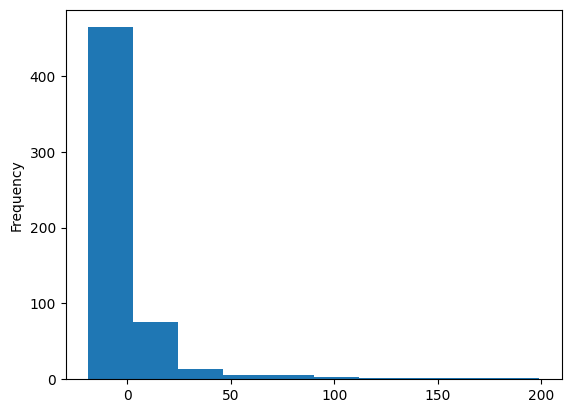

In [6]:
df["dep_delay"].plot.hist()
df["dep_delay"].mean()

## Boolean Masking

In [7]:
df["carrier"] == "UA"

0      False
1       True
2      False
3       True
4      False
       ...  
573    False
574    False
575     True
576    False
577    False
Name: carrier, Length: 578, dtype: bool

In [8]:
(df["carrier"] == "UA").sum()

np.int64(123)

In [9]:
(df["carrier"] == "UA").mean()

np.float64(0.21280276816608998)

In [10]:
df[df["carrier"] == "UA"]

,carrier,flight,origin,dest,dep_delay
1,UA,1014,LGA,IAH,-3.0
3,UA,303,JFK,SFO,-8.0
8,UA,1187,LGA,ORD,-5.0
9,UA,258,EWR,MCO,-2.0
15,UA,665,EWR,SFO,-1.0
...,...,...,...,...,...
537,UA,1631,EWR,IAH,-3.0
549,UA,1409,EWR,TPA,-1.0
552,UA,1071,EWR,BQN,5.0
562,UA,1066,EWR,BOS,-5.0


In [11]:
df[df["carrier"] == "UA"]["dep_delay"].mean()

np.float64(5.590163934426229)

## Split-Apply-Combine

How would we calculate the mean delay of every carrier?

In [12]:
for carrier in df["carrier"].unique():
  print(carrier, df[df["carrier"] == carrier]["dep_delay"].mean())

US -2.324324324324324
UA 5.590163934426229
AA -1.337837837837838
DL 3.295238095238095
B6 1.5378787878787878
EV 1.2476190476190476


Iterating over a `groupby()` produces (up to ordering) exactly the same as above.

In [13]:
for carrier, carrier_df in df.groupby("carrier"):
    print(carrier, carrier_df['dep_delay'].mean())

AA -1.337837837837838
B6 1.5378787878787878
DL 3.295238095238095
EV 1.2476190476190476
UA 5.590163934426229
US -2.324324324324324


The return value of `.groupby()` is not simply this iterator: you
can directly aggregate by using methods like `.mean()`:

In [15]:
df.groupby("carrier")["dep_delay"].mean()

carrier
AA   -1.337838
B6    1.537879
DL    3.295238
EV    1.247619
UA    5.590164
US   -2.324324
Name: dep_delay, dtype: float64

<Axes: xlabel='carrier'>

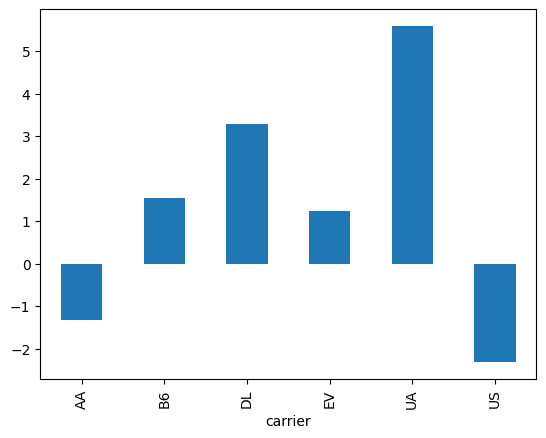

In [16]:
df.groupby("carrier")["dep_delay"].mean().plot.bar()

In [17]:
df.groupby(["carrier", "origin"])["dep_delay"].mean()

carrier  origin
AA       EWR       -3.375000
         JFK        1.771429
         LGA       -4.322581
B6       EWR       -0.823529
         JFK       -0.836735
         LGA       17.588235
DL       EWR       19.222222
         JFK        4.980000
         LGA       -1.652174
EV       EWR        1.483146
         JFK        0.000000
         LGA       -0.083333
UA       EWR        7.525773
         JFK        1.909091
         LGA       -4.928571
US       EWR       -5.000000
         JFK        5.400000
         LGA       -5.312500
Name: dep_delay, dtype: float64

<Axes: xlabel='carrier'>

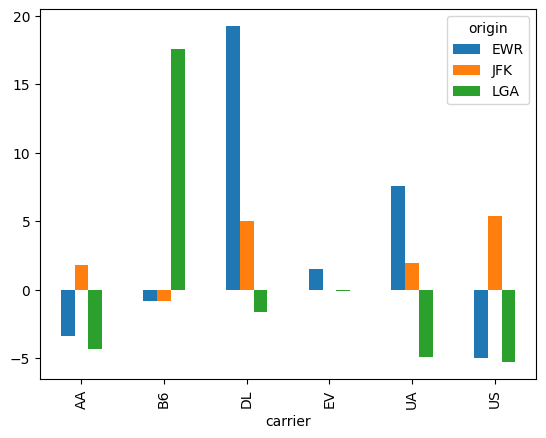

In [20]:
(df.groupby(["carrier", "origin"])["dep_delay"].mean().
 unstack("origin").
 plot.bar())

## In-Class Exercise

## Visualizing Conditional Distributions

What do you think `axes` is going to be?

origin
EWR    Axes(0.125,0.11;0.775x0.77)
JFK    Axes(0.125,0.11;0.775x0.77)
LGA    Axes(0.125,0.11;0.775x0.77)
Name: dep_delay, dtype: object

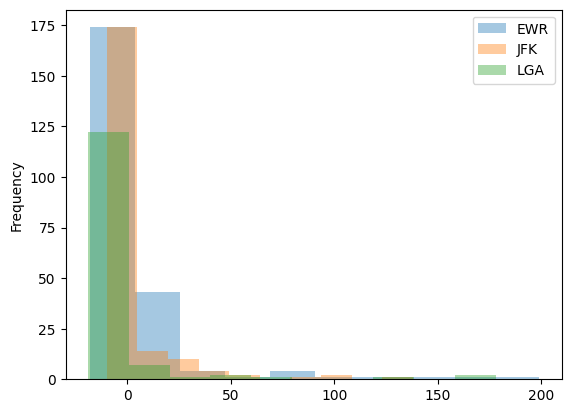

In [21]:
axes = df.groupby("origin")["dep_delay"].plot.hist(legend=True,
                                                   alpha=0.4)

axes

In [22]:
axes.loc['EWR'].set_xlabel("Departure Delay")

Text(0.5, 4.444444444444445, 'Departure Delay')

Text(0, 0.5, 'Density')

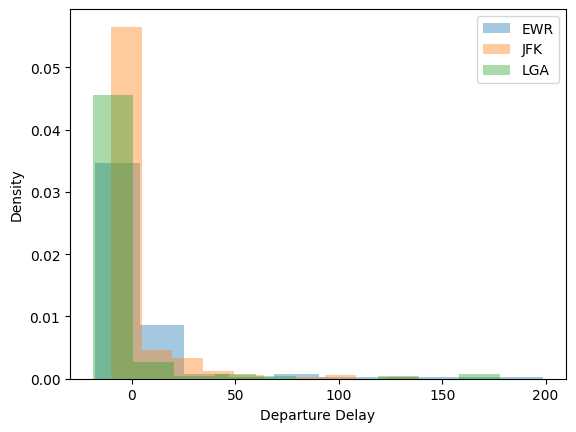

In [23]:
axes = df.groupby("origin")["dep_delay"].plot.hist(legend=True,
                                                   alpha=0.4,
                                                   density=True)
axes.loc['EWR'].set_xlabel("Departure Delay")
axes.loc['EWR'].set_ylabel("Density")